In [6]:
from pathlib import Path
import xarray as xr

path = Path('/scratch/s1803229/fsm2/S01/2020_12/driving_data.nc')
with xr.open_dataset(path) as ds:
    print(ds)
    for name in ['t2m', 'd2m', 'sf', 'tp', 'ssrd', 'strd', 'u10', 'v10', 'sp', 'VAI', 'vegh']:
        print(name, ds[name].dims, ds[name].attrs)
    print('Latitude rows:', ds.sizes['latitude'])
    print('Longitude columns:', ds.sizes['longitude'])
    print('VAI range:', float(ds.VAI.min()), float(ds.VAI.max()))
    print('Height range:', float(ds.vegh.min()), float(ds.vegh.max()))

<xarray.Dataset> Size: 92MB
Dimensions:     (valid_time: 744, latitude: 38, longitude: 81)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2020-12-01 ... 2020-12-31T23:...
  * latitude    (latitude) float64 304B 64.8 64.7 64.6 64.5 ... 61.3 61.2 61.1
  * longitude   (longitude) float64 648B -126.6 -126.5 -126.4 ... -118.7 -118.6
Data variables:
    d2m         (valid_time, latitude, longitude) float32 9MB ...
    t2m         (valid_time, latitude, longitude) float32 9MB ...
    sf          (valid_time, latitude, longitude) float32 9MB ...
    ssrd        (valid_time, latitude, longitude) float32 9MB ...
    strd        (valid_time, latitude, longitude) float32 9MB ...
    u10         (valid_time, latitude, longitude) float32 9MB ...
    v10         (valid_time, latitude, longitude) float32 9MB ...
    sp          (valid_time, latitude, longitude) float32 9MB ...
    tp          (valid_time, latitude, longitude) float32 9MB ...
    w10         (valid_time, latitude, longitu

In [7]:
eligible = (
    ds.VAI.notnull() & ds.vegh.notnull()
    & (ds.VAI > 0) & (ds.vegh > 2)
)
print("Missing canopy heights:", int(ds.vegh.isnull().sum()))
print("Eligible cells:", int(eligible.sum()), "/", eligible.size)

Missing canopy heights: 4
Eligible cells: 3074 / 3078


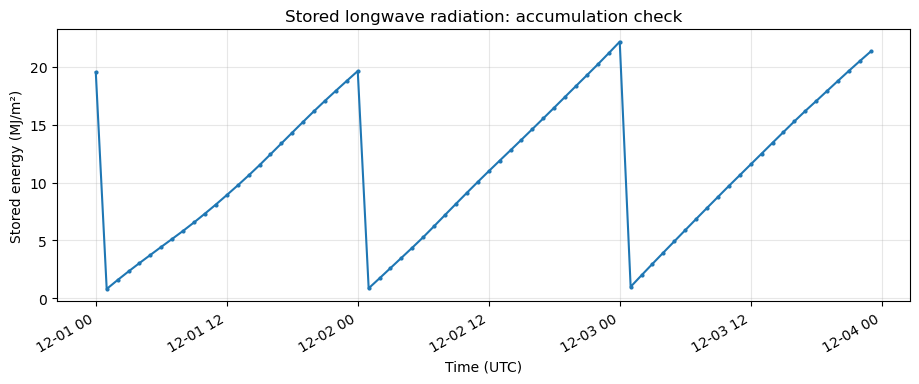

valid_time
2020-12-01 00:00:00    1.954277e+07
2020-12-01 01:00:00    8.071863e+05
2020-12-01 02:00:00    1.580573e+06
2020-12-01 03:00:00    2.322361e+06
2020-12-01 22:00:00    1.793372e+07
2020-12-01 23:00:00    1.878747e+07
2020-12-02 00:00:00    1.963240e+07
2020-12-02 01:00:00    8.661254e+05
2020-12-02 02:00:00    1.734324e+06
2020-12-02 03:00:00    2.615939e+06
2020-12-02 22:00:00    2.021472e+07
2020-12-02 23:00:00    2.117993e+07
2020-12-03 00:00:00    2.216419e+07
2020-12-03 01:00:00    9.953471e+05
2020-12-03 02:00:00    1.993044e+06
2020-12-03 03:00:00    2.978626e+06
2020-12-03 22:00:00    2.049659e+07
2020-12-03 23:00:00    2.132340e+07


In [8]:
import matplotlib.pyplot as plt

time = "valid_time" if "valid_time" in ds.dims else "time"

# Average over the region; inspect only the first three days.
lw = (
    ds.strd.isel({time: slice(0, 72)})
    .mean(("latitude", "longitude"))
    .compute()
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(lw[time].values, lw.values / 1e6, marker=".", markersize=4)
ax.set(
    title="Stored longwave radiation: accumulation check",
    xlabel="Time (UTC)",
    ylabel="Stored energy (MJ/m²)",
)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

# Show the values around two daily boundaries.
s = lw.to_series()
print(s[(s.index.hour <= 3) | (s.index.hour >= 22)].to_string())

In [10]:
import numpy as np
import pandas as pd
from IPython.display import display

SELECT_BY = "sf"       # "tp": wettest period; "sf": snowiest period.
TOL = 1e-7            # Metres water equivalent; matches the runner.

time = "valid_time" if "valid_time" in ds.dims else "time"

# Choose a valid forest cell with substantial precipitation.
eligible = (
    np.isfinite(ds.VAI) & np.isfinite(ds.vegh)
    & (ds.VAI > 0) & (ds.vegh > 2)
)
score = (
    ds[SELECT_BY].max(time).where(eligible)
    .transpose("latitude", "longitude").compute()
)
if not np.isfinite(score.values).any() or float(score.max()) <= 0:
    raise ValueError("No precipitation found at eligible cells; try another month.")

iy, ix = np.unravel_index(np.nanargmax(score.values), score.shape)

point = ds[["tp", "sf"]].isel(latitude=iy, longitude=ix).compute()
stored = point.to_dataframe()[["tp", "sf"]].sort_index()

if stored.index.has_duplicates:
    raise ValueError("Duplicate timestamps.")

# Assign 01:00 ... next-day 00:00 to the same forecast cycle.
cycles = []
for day, group in stored.groupby(
    (stored.index - pd.Timedelta(hours=1)).normalize()
):
    expected = pd.date_range(day + pd.Timedelta(hours=1), periods=24, freq="h")
    if group.index.equals(expected) and np.isfinite(group.to_numpy()).all():
        cycles.append((day, group))

if not cycles:
    raise ValueError("No complete, finite 24-hour forecast cycle found.")

day, raw = max(cycles, key=lambda item: item[1][SELECT_BY].max())

# Test the cumulative interpretation: 01 UTC is the first hourly amount.
increments = raw.diff()
increments.iloc[0] = raw.iloc[0]

table = pd.DataFrame({
    "Stored tp (mm)": raw.tp * 1000,
    "Hourly tp (mm)": increments.tp * 1000,
    "Stored sf (mm SWE)": raw.sf * 1000,
    "Hourly sf (mm SWE)": increments.sf * 1000,
})
print(f"Cell: {float(point.latitude):.3f}, {float(point.longitude):.3f}")
print(f"Forecast cycle: {day:%Y-%m-%d} 01 UTC → next day 00 UTC")
display(table.round(6))

summary = pd.DataFrame({
    "Sum of hourly increments (mm)": increments.sum() * 1000,
    "Stored ending 00 UTC total (mm)": raw.iloc[-1] * 1000,
    "Difference (mm)": (increments.sum() - raw.iloc[-1]) * 1000,
    "Minimum hourly increment (mm)": increments.min() * 1000,
})
display(summary)

negative = increments < -TOL
rain_negative = (increments.tp - increments.sf) < -TOL

if negative.to_numpy().any():
    print("STOP: significant negative increments under the cumulative interpretation:")
    display((increments * 1000).where(negative).dropna(how="all"))
    print("Investigate the accumulation convention; these values have NOT been clipped.")
elif rain_negative.any():
    print("STOP: hourly snowfall exceeds total precipitation beyond tolerance.")
else:
    print("PASS: no significant negative increments; snowfall does not exceed total precipitation.")
    if (increments.to_numpy() < 0).any():
        print("Tiny negative increments exist within the runner's rounding tolerance.")

Cell: 61.200, -126.600
Forecast cycle: 2020-12-02 01 UTC → next day 00 UTC


,Stored tp (mm),Hourly tp (mm),Stored sf (mm SWE),Hourly sf (mm SWE)
valid_time,,,,
2020-12-02 01:00:00,0.467526,0.467526,0.467526,0.467526
2020-12-02 02:00:00,1.186423,0.718897,1.186422,0.718896
2020-12-02 03:00:00,2.288684,1.102261,2.288684,1.102262
2020-12-02 04:00:00,3.668025,1.379341,3.668029,1.379345
2020-12-02 05:00:00,4.960552,1.292527,4.960548,1.292519
2020-12-02 06:00:00,5.880632,0.920080,5.880632,0.920083
2020-12-02 07:00:00,6.373252,0.492620,6.372817,0.492185
2020-12-02 08:00:00,6.745192,0.371940,6.743614,0.370797
2020-12-02 09:00:00,7.048434,0.303242,6.981738,0.238124


,Sum of hourly increments (mm),Stored ending 00 UTC total (mm),Difference (mm),Minimum hourly increment (mm)
tp,7.658380,7.658380,0.0,0.0
sf,7.180445,7.180445,0.0,0.0


PASS: no significant negative increments; snowfall does not exceed total precipitation.


In [1]:
from pathlib import Path
import pandas as pd
import xarray as xr

root = Path("/scratch/s1803229/fsm2/S01")
parts = []

for path in sorted(root.glob("????_??/driving_data.nc")):
    with xr.open_dataset(path) as ds:
        parts.append(ds["ssrd"].isel(latitude=0, longitude=0).to_series())

ssrd = pd.concat(parts).astype("float64")
if not ssrd.index.to_series().diff().iloc[1:].eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Time axis has a gap, duplicate, or out-of-order hour.")

# Match the runner: 01 UTC starts a new accumulation cycle.
increment = ssrd.diff()
reset = ssrd.index.hour == 1
increment.loc[reset] = ssrd.loc[reset]

bad = increment[increment < -1.0]
print(f"Hourly increments below −1 J/m²: {len(bad):,}")
if not bad.empty:
    t = bad.idxmin()
    print(f"Largest decrease: {bad.loc[t]:.4f} J/m² at {t} UTC")
    print("Crosses monthly file boundary:", t.day == 1 and t.hour == 0)
    window = pd.concat(
        {"stored_J_m2": ssrd, "increment_J_m2": increment}, axis=1
    )
    print(window.loc[t - pd.Timedelta(hours=3):t + pd.Timedelta(hours=3)])

Hourly increments below −1 J/m²: 40
Largest decrease: -2.4375 J/m² at 2026-03-14 14:00:00 UTC
Crosses monthly file boundary: False
                      stored_J_m2  increment_J_m2
valid_time                                       
2026-03-14 11:00:00  7.738660e+05          0.0000
2026-03-14 12:00:00  7.738660e+05          0.0000
2026-03-14 13:00:00  7.738660e+05          0.0000
2026-03-14 14:00:00  7.738636e+05         -2.4375
2026-03-14 15:00:00  7.742815e+05        417.9375
2026-03-14 16:00:00  8.849305e+05     110649.0000
2026-03-14 17:00:00  1.244030e+06     359099.5000


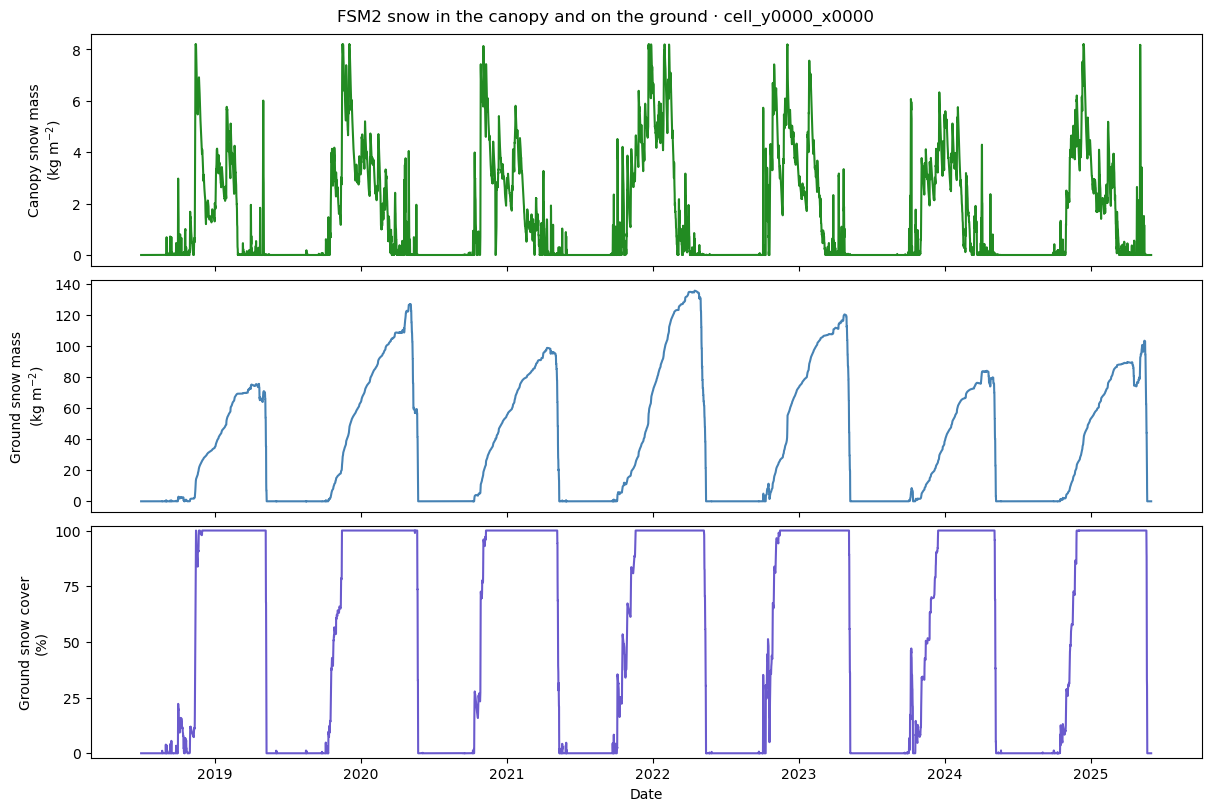

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr

folder = Path("/scratch/s1803229/fsm2_results/S01")
path = next(iter(sorted(folder.glob("cell_y*_x*.nc"))), None)
if path is None:
    raise FileNotFoundError(f"No per-cell NetCDF files found in {folder}")

with xr.open_dataset(path) as ds:
    snow = (
        ds[["canopy_snow_mass", "ground_snow_mass", "snow_depth"]]
        .sel(time=slice("2018-07-01", "2025-05-31"))
        .load()
    )

# FSM2 SNFRAC=1 with default hfsn=0.1 m: 10 cm gives full ground cover.
snow["ground_snow_cover_fraction"] = (snow["snow_depth"] / 0.1).clip(max=1)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)

axes[0].plot(snow.time, snow.canopy_snow_mass, color="forestgreen")
axes[0].set_ylabel("Canopy snow mass\n(kg m$^{-2}$)")

axes[1].plot(snow.time, snow.ground_snow_mass, color="steelblue")
axes[1].set_ylabel("Ground snow mass\n(kg m$^{-2}$)")

axes[2].plot(snow.time, 100 * snow.ground_snow_cover_fraction, color="slateblue")
axes[2].set_ylabel("Ground snow cover\n(%)")
axes[2].set_ylim(-2, 102)
axes[2].set_yticks([0, 25, 50, 75, 100])
axes[2].set_xlabel("Date")

fig.suptitle(f"FSM2 snow in the canopy and on the ground · {path.stem}")
plt.show()

In [5]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

path = Path("/scratch/s1803229/fsm2_results/S01.nc")
if not path.is_file():
    raise FileNotFoundError(f"Expected assembled regional file: {path}")

ds = xr.open_dataset(path)
display(ds)

# status = ds.cell_status.load()
# print(f"Period: {ds.time.values[0]} to {ds.time.values[-1]}")
# print(f"Excluded by forest mask:       {int((status == 0).sum()):,}")
# print(f"Eligible but missing output:   {int((status == 1).sum()):,}")
# print(f"Successfully assembled:        {int((status == 2).sum()):,}")

# audit = json.loads(ds.attrs["ssrd_fill_audit"])
# fills = pd.DataFrame(
#     [{"cell": cell, **gap} for cell, record in audit.items() for gap in record["gaps"]]
# )

# print(f"\nCells with an SSRD fill:        {len(audit)}")
# print(f"Total hourly values filled:    {int(fills['hours'].sum()) if not fills.empty else 0}")

# if not fills.empty:
#     display(fills.sort_values(["start_utc", "cell"]).reset_index(drop=True))

<xarray.Dataset> Size: 3GB
Dimensions:                (latitude: 38, longitude: 81, time: 70127)
Coordinates:
  * latitude               (latitude) float64 304B 64.8 64.7 64.6 ... 61.2 61.1
  * longitude              (longitude) float64 648B -126.6 -126.5 ... -118.6
  * time                   (time) datetime64[ns] 561kB 2018-07-01T01:00:00 .....
Data variables:
    VAI                    (latitude, longitude) float32 12kB ...
    vegh                   (latitude, longitude) float32 12kB ...
    simulated_forest_mask  (latitude, longitude) int8 3kB ...
    cell_status            (latitude, longitude) int8 3kB ...
    snow_depth             (time, latitude, longitude) float32 863MB ...
    ground_snow_mass       (time, latitude, longitude) float32 863MB ...
    canopy_snow_mass       (time, latitude, longitude) float32 863MB ...
Attributes:
    run_signature:             4abd84f4e45e337019812bcc3b8c7a8c20d684235122db...
    source_commit:             a76945e75b36628161f4679428ed72dce090b368
    spinup_cycles:             2
    accumulation:              cumulative
    time_convention:           UTC interval end; state after one-hour step; s...
    forcing_note:              Instantaneous T, humidity, pressure and wind s...
    model_options:             /* Process options                            ...
    assembly_inputs:           bc7c009fdd075107e6832a59f85df841dc3410555b7782...
    assembly_completed_cells:  3074
    ssrd_fill_audit:           {"cell_y0000_x0006": {"method": "neighbour_pla...

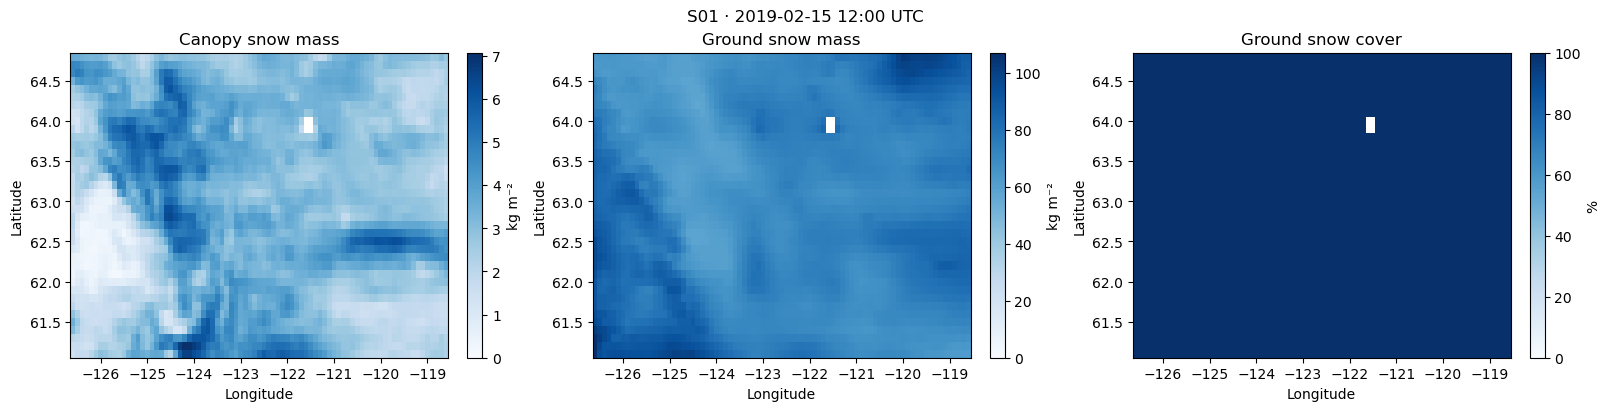

In [3]:
WHEN = "2019-02-15T12:00"

snow_vars = ["canopy_snow_mass", "ground_snow_mass", "snow_depth"]
snapshot = ds[snow_vars].sel(time=WHEN).load()
ground_cover = 100 * (snapshot.snow_depth / 0.10).clip(min=0, max=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)

for ax, data, title, units, vmax in [
    (axes[0], snapshot.canopy_snow_mass, "Canopy snow mass", "kg m⁻²", None),
    (axes[1], snapshot.ground_snow_mass, "Ground snow mass", "kg m⁻²", None),
    (axes[2], ground_cover, "Ground snow cover", "%", 100),
]:
    data.plot(
        ax=ax, x="longitude", y="latitude", cmap="Blues",
        vmin=0, vmax=vmax, cbar_kwargs={"label": units},
    )
    ax.set(title=title, xlabel="Longitude", ylabel="Latitude")

fig.suptitle(f"S01 · {WHEN.replace('T', ' ')} UTC")
plt.show()

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

path = Path("/scratch/s1803229/fsm2_results/S01.nc")
start, end = "2018-10-01", "2019-05-31"
frequency = "7D"  # "1D" for daily, "7D" for weekly, "MS" for monthly
fps = 4
gif = path.with_name(f"{path.stem}_snow_{start}_{end}_{frequency}.gif")

# Reduce the hourly data to one map per frame before plotting.
with xr.open_dataset(path, chunks="auto") as ds:
    snow = ds[["canopy_snow_mass", "snow_depth"]].sel(time=slice(start, end))
    if snow.sizes["time"] == 0:
        raise ValueError(f"No data between {start} and {end}")

    # SNFRAC=1: calculate cover at each hour, then average over the frame.
    snow["ground_cover_pct"] = 100 * (snow.snow_depth / 0.10).clip(min=0, max=1)
    frames = (
        snow[["canopy_snow_mass", "ground_cover_pct"]]
        .resample(time=frequency)
        .mean()
        .transpose("time", "latitude", "longitude")
        .compute()
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
layers = [
    (frames.canopy_snow_mass, "Canopy snow mass", "kg m⁻²", "Oranges"),
    (frames.ground_cover_pct, "Ground snow cover", "%", "Blues"),
]
# # 1 if canopy snow mass is positive, 0 if zero. Missing cells stay grey.
# mass = frames.canopy_snow_mass
# canopy_snow_present = (mass > 0).astype(float).where(mass.notnull())

# layers = [
#     (canopy_snow_present, "Canopy snow present", "0 = absent, 1 = present", "Oranges"),
#     (frames.ground_cover_pct, "Ground snow cover", "%", "Blues"),
# ]
meshes = []

for ax, (field, title, units, cmap) in zip(axes, layers):
    vmax = 100 if units == "%" else max(float(field.max()), 0.01)
    mesh = ax.pcolormesh(
        frames.longitude, frames.latitude, field.isel(time=0),
        shading="auto", cmap=cmap, vmin=0, vmax=vmax,
    )
    ax.set(title=title, xlabel="Longitude", ylabel="Latitude", facecolor="lightgrey")
    ax.set_aspect(1 / np.cos(np.deg2rad(float(frames.latitude.mean()))))
    fig.colorbar(mesh, ax=ax, label=units)
    meshes.append(mesh)

heading = fig.suptitle("")

def update(i):
    for mesh, (field, *_) in zip(meshes, layers):
        mesh.set_array(field.isel(time=i).values.ravel())
    date = np.datetime_as_string(frames.time.values[i], unit="D")
    heading.set_text(f"{path.stem} · Mean for period beginning {date}")

from IPython.display import HTML, display

animation = FuncAnimation(
    fig, update, frames=frames.sizes["time"], interval=1000 / fps, repeat=True
)
plt.close(fig)
display(HTML(animation.to_jshtml()))